# Predictive Maintenance for Engine Health
## Interim Submission

**Objective:** Predictive Engine Failure Classification & Experimentation Tracking  

In industrial machinery, commercial transport fleets, and power generation assets, rotating engines represent high-criticality tier-1 physical assets. Traditional maintenance regimes follow one of two suboptimal operational paradigms:
1. **Run-to-Failure (Reactive Maintenance):** Incurring severe secondary mechanical damage, emergency logistics costs, and catastrophic functional failure.
2. **Time-Based / Calendar-Based Maintenance (Static PM):** Replacing costly parts and lubrication fluids at predetermined runtime intervals, leading to premature component disposal, excessive labor overhead, and missed mid-cycle anomalous degradation.

**Asset Performance Management (APM) & Condition-Based Maintenance (CBM):**
This project applies **Reliability-Centered Maintenance (RCM)** and the **P-F Curve (Potential Failure to Functional Failure Interval)** principle. By continuously ingesting edge sensor telemetry—**Engine RPM, Lubricating Oil Pressure, Fuel Pressure, Coolant Pressure, Lub Oil Temperature, and Coolant Temperature**—we train machine learning classifiers to detect anomalous degradation at Point $P$ (Potential Failure) hundreds of operational hours before Point $F$ (Functional Breakdown).

### Problem Statement & Business Context
Unscheduled engine failures and roadside breakdowns impose massive financial losses across commercial logistics fleets, industrial generator operators, and private vehicle owners. Unplanned breakdowns cause expensive towing, secondary mechanical damage, critical downtime, and safety hazards.

**Predictive Maintenance (PdM)** uses real-time telemetry from onboard engine sensors (**Engine RPM, Lubricating Oil Pressure, Fuel Pressure, Coolant Pressure, Lub Oil Temperature, and Coolant Temperature**) to detect early mechanical and thermodynamic deterioration. By forecasting failure states before complete breakdown, maintenance crews can service engines proactively during scheduled maintenance windows.


---
## 0. Environment Setup & Google Colab Initialization



In [40]:
# 0.1 Install & Import Core Dependencies
import os
import sys
import json
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette('deep')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['font.size'] = 11

# Scikit-Learn & Machine Learning Suite
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve, precision_recall_curve
)
import joblib

# Check & Install XGBoost if needed
try:
    from xgboost import XGBClassifier
    print("XGBoost is installed and ready.")
except ImportError:
    !pip install -q xgboost
    from xgboost import XGBClassifier
    print("XGBoost installed.")

# Initialize standard project directories
os.makedirs('data', exist_ok=True)
os.makedirs('models', exist_ok=True)
os.makedirs('src', exist_ok=True)
os.makedirs('.github/workflows', exist_ok=True)
print("Project directories ready: /data, /models, /src, /.github/workflows")


XGBoost is installed and ready.
Project directories ready: /data, /models, /src, /.github/workflows


### Dataset Ingestion for Google Colab



In [12]:
df = pd.read_csv('/content/data/engine_data.csv')

In [13]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
# checking the shape of the data
df.shape

(19535, 7)

The datset consists of 19535 rows and 7 columns

---
## 1. Data Registration & Schema Validation

### Sensor Telemetry Data Dictionary:
| Column Name | Physical Metric | Measurement Unit | Operational Context |
| :--- | :--- | :--- | :--- |
| **Engine rpm** | Crankshaft Speed | Revolutions / Min (RPM) | Engine rotational speed indicating workload. |
| **Lub oil pressure** | Lubrication Pressure | bar / kPa | Pressure of lubricating oil preventing metallic friction. |
| **Fuel pressure** | Fuel Delivery Pressure | bar / kPa | Pressure of fuel supplied to injectors for combustion. |
| **Coolant pressure** | Cooling Loop Pressure | bar / kPa | Pressure maintained by water pump in cooling channels. |
| **lub oil temp** | Oil Sump Temperature | °C | Thermal state of engine oil affecting viscosity. |
| **Coolant temp** | Coolant Temperature | °C | Operating temperature of engine coolant. |
| **Engine Condition** | Target Label | Binary (0 / 1) | **0 = Normal / Active Operation**, **1 = Faulty / Maintenance Required** |


In [15]:
# inspecting the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19535 entries, 0 to 19534
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Engine rpm        19535 non-null  int64  
 1   Lub oil pressure  19535 non-null  float64
 2   Fuel pressure     19535 non-null  float64
 3   Coolant pressure  19535 non-null  float64
 4   lub oil temp      19535 non-null  float64
 5   Coolant temp      19535 non-null  float64
 6   Engine Condition  19535 non-null  int64  
dtypes: float64(5), int64(2)
memory usage: 1.0 MB


There are 6 numeric variables

In [16]:
# checking if there are any missing values
df.isnull().sum()

,0
Engine rpm,0
Lub oil pressure,0
Fuel pressure,0
Coolant pressure,0
lub oil temp,0
Coolant temp,0
Engine Condition,0


There are no missing values in the data.

In [17]:
# checking the first 5 rows of the data
df.head()

,Engine rpm,Lub oil pressure,Fuel pressure,Coolant pressure,lub oil temp,Coolant temp,Engine Condition
0,700,2.493592,11.790927,3.178981,84.144163,81.632187,1
1,876,2.941606,16.193866,2.464504,77.640934,82.445724,0
2,520,2.961746,6.553147,1.064347,77.752266,79.645777,1
3,473,3.707835,19.510172,3.727455,74.129907,71.774629,1
4,619,5.672919,15.738871,2.052251,78.396989,87.000225,0


In [20]:
# Checking Duplicate Rows
dup_count = df.duplicated().sum()
print(f" Duplicate Rows:      {dup_count} duplicate rows detected.")

 Duplicate Rows:      0 duplicate rows detected.


There are no duplicate rows.

---
## 2. Exploratory Data Analysis



In [22]:
# Dataset Information & Summary Statistics
print("Dataset Structural Info:")
df_registered.info()
display(df_registered.describe().T.style.format('{:.2f}').background_gradient(cmap='Blues'))


Dataset Structural Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19535 entries, 0 to 19534
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Engine rpm        19535 non-null  int64  
 1   Lub oil pressure  19535 non-null  float64
 2   Fuel pressure     19535 non-null  float64
 3   Coolant pressure  19535 non-null  float64
 4   lub oil temp      19535 non-null  float64
 5   Coolant temp      19535 non-null  float64
 6   Engine Condition  19535 non-null  int64  
dtypes: float64(5), int64(2)
memory usage: 1.0 MB


,count,mean,std,min,25%,50%,75%,max
Engine rpm,19535.00,791.24,267.61,61.00,593.00,746.00,934.00,2239.00
Lub oil pressure,19535.00,3.30,1.02,0.00,2.52,3.16,4.06,7.27
Fuel pressure,19535.00,6.66,2.76,0.00,4.92,6.20,7.74,21.14
Coolant pressure,19535.00,2.34,1.04,0.00,1.60,2.17,2.85,7.48
lub oil temp,19535.00,77.64,3.11,71.32,75.73,76.82,78.07,89.58
Coolant temp,19535.00,78.43,6.21,61.67,73.90,78.35,82.92,195.53
Engine Condition,19535.00,0.63,0.48,0.00,0.00,1.00,1.00,1.00


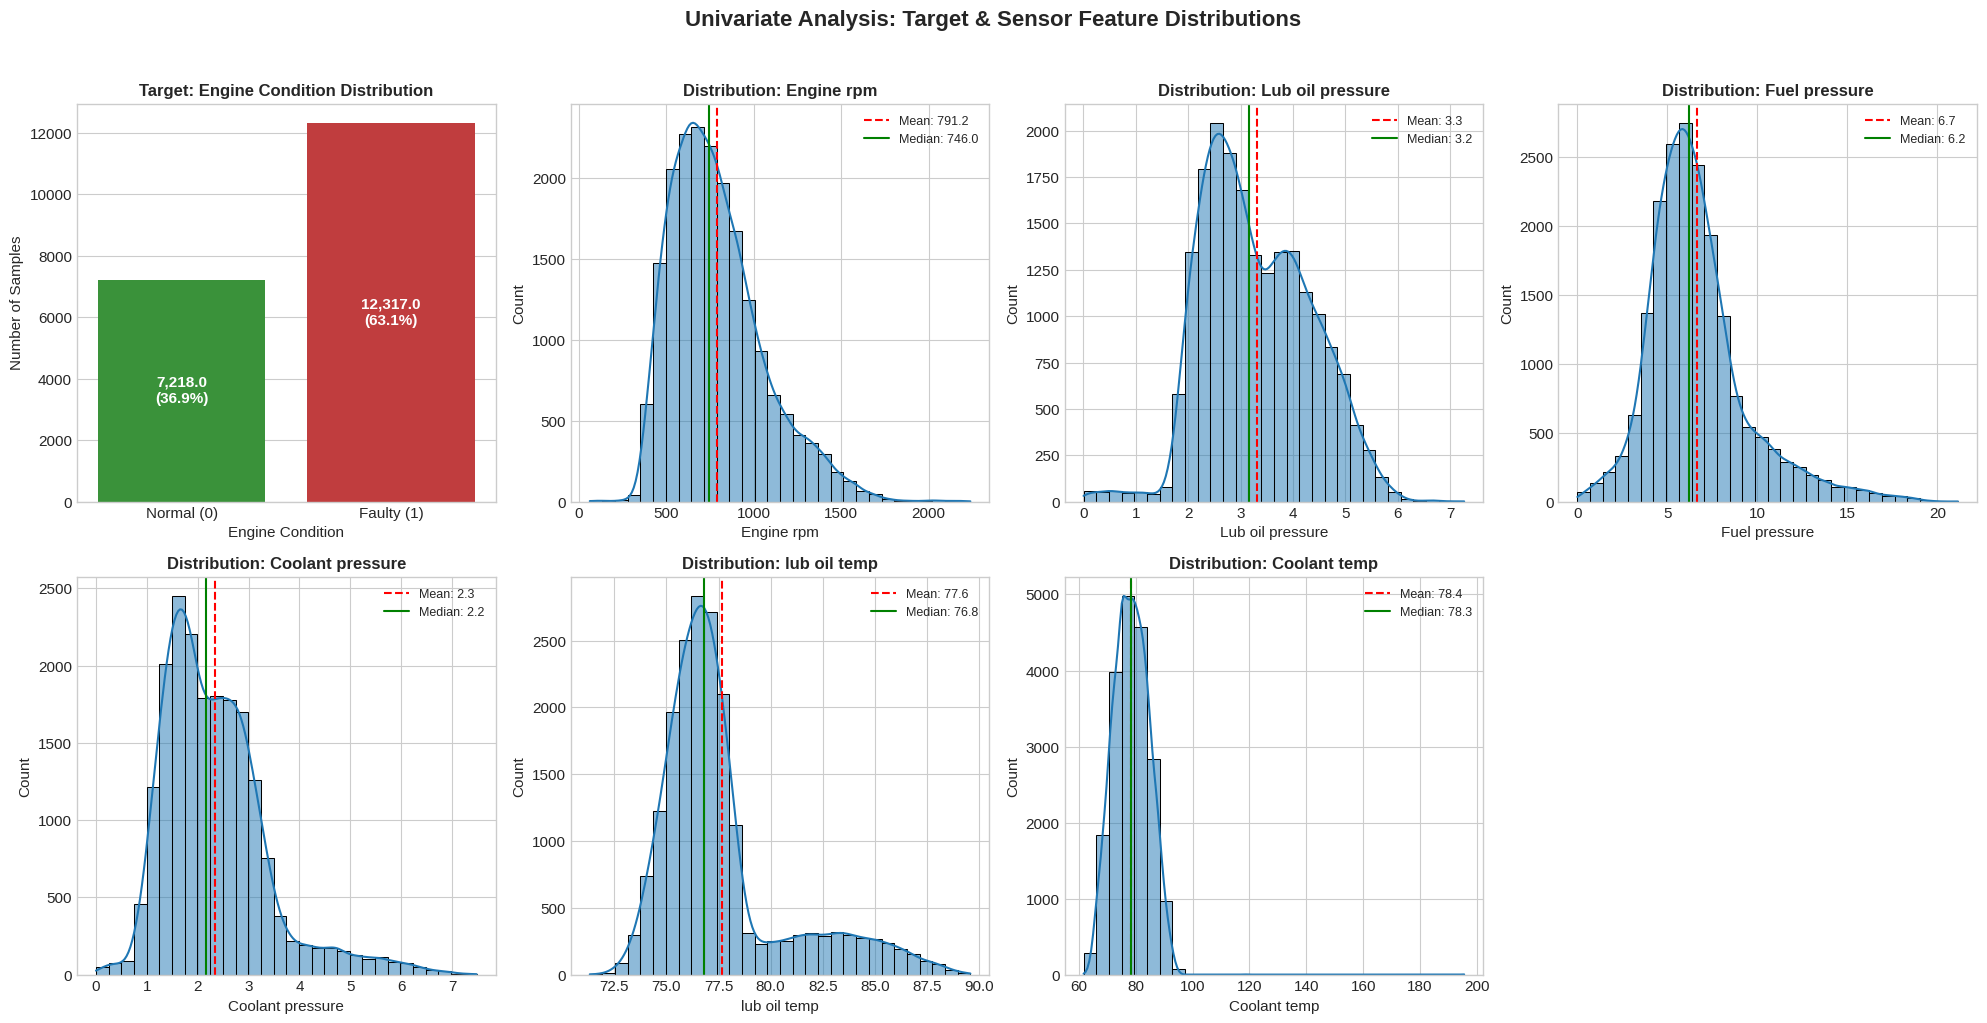

In [27]:
# Univariate Analysis: Target Class Distribution & Feature Histograms
sensor_cols = [c for c in df_registered.columns if c != 'Engine Condition']

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

# Target Distribution Plot
sns.countplot(x='Engine Condition', data=df_registered, ax=axes[0], palette=['#2ca02c', '#d62728'])
axes[0].set_title('Target: Engine Condition Distribution', fontweight='bold', fontsize=12)
axes[0].set_xticklabels(['Normal (0)', 'Faulty (1)'])
axes[0].set_ylabel('Number of Samples')
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height():,}\n({p.get_height()/len(df_registered)*100:.1f}%)',
                     (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha='center', va='center', color='white', fontweight='bold', fontsize=11)

# Sensor Feature Distributions with KDE
for i, col in enumerate(sensor_cols):
    ax = axes[i + 1]
    sns.histplot(df_registered[col], kde=True, ax=ax, color='#1f77b4', bins=30)
    ax.axvline(df_registered[col].mean(), color='red', linestyle='--', label=f"Mean: {df_registered[col].mean():.1f}")
    ax.axvline(df_registered[col].median(), color='green', linestyle='-', label=f"Median: {df_registered[col].median():.1f}")
    ax.set_title(f'Distribution: {col}', fontweight='bold', fontsize=12)
    ax.set_xlabel(col)
    ax.legend(fontsize=9)

axes[7].axis('off')  # Hide unused 8th axis
plt.suptitle('Univariate Analysis: Target & Sensor Feature Distributions', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


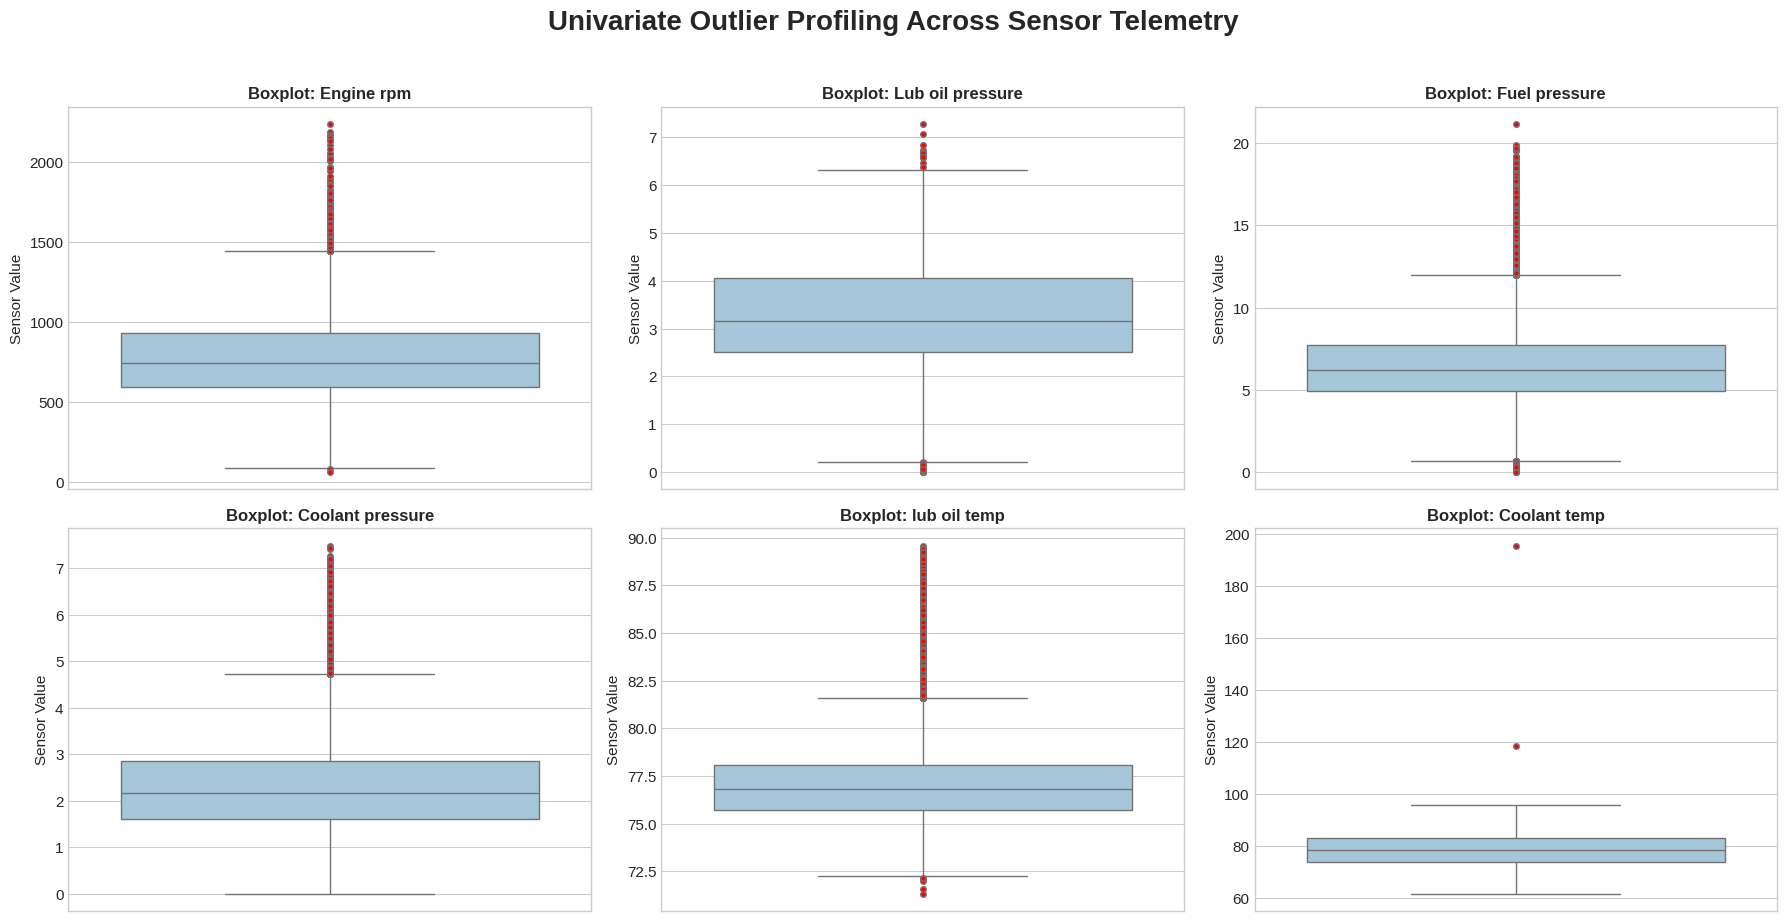

In [28]:
# Univariate Outlier Analysis (Boxplots)
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(sensor_cols):
    sns.boxplot(y=df_registered[col], ax=axes[i], color='#9ecae1', flierprops={'markerfacecolor':'red', 'markersize':4})
    axes[i].set_title(f'Boxplot: {col}', fontweight='bold', fontsize=12)
    axes[i].set_ylabel('Sensor Value')

plt.suptitle('Univariate Outlier Profiling Across Sensor Telemetry', fontsize=20, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


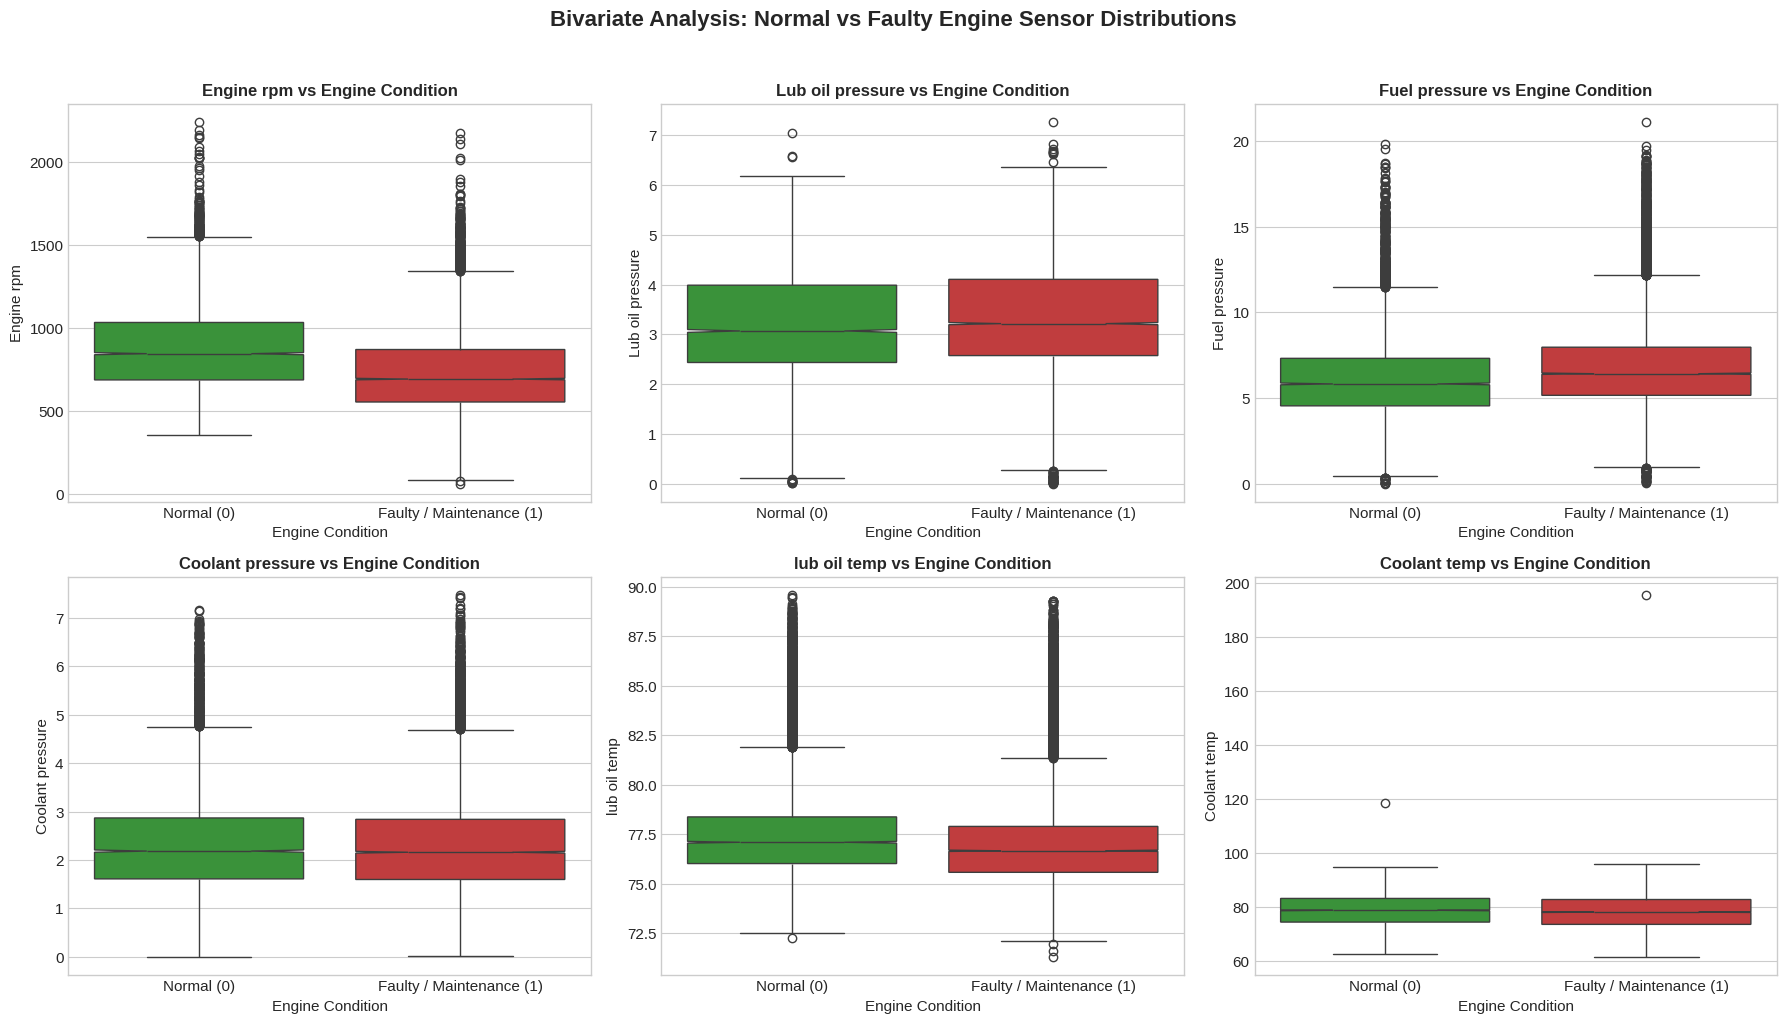

In [29]:
# Bivariate Analysis: Sensor Distribution Grouped by Engine Condition
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, col in enumerate(sensor_cols):
    sns.boxplot(
        x='Engine Condition',
        y=col,
        data=df_registered,
        ax=axes[i],
        palette=['#2ca02c', '#d62728'],
        notch=True
    )
    axes[i].set_title(f'{col} vs Engine Condition', fontweight='bold', fontsize=12)
    axes[i].set_xticklabels(['Normal (0)', 'Faulty / Maintenance (1)'])
    axes[i].set_xlabel('Engine Condition')

plt.suptitle('Bivariate Analysis: Normal vs Faulty Engine Sensor Distributions', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [30]:
# Bivariate Statistical Summary Table
bivariate_summary = df_registered.groupby('Engine Condition')[sensor_cols].agg(['mean', 'median', 'std']).T
bivariate_summary.columns = ['Normal (0)', 'Faulty (1)']
display(bivariate_summary.style.format('{:.2f}').background_gradient(cmap='Oranges'))


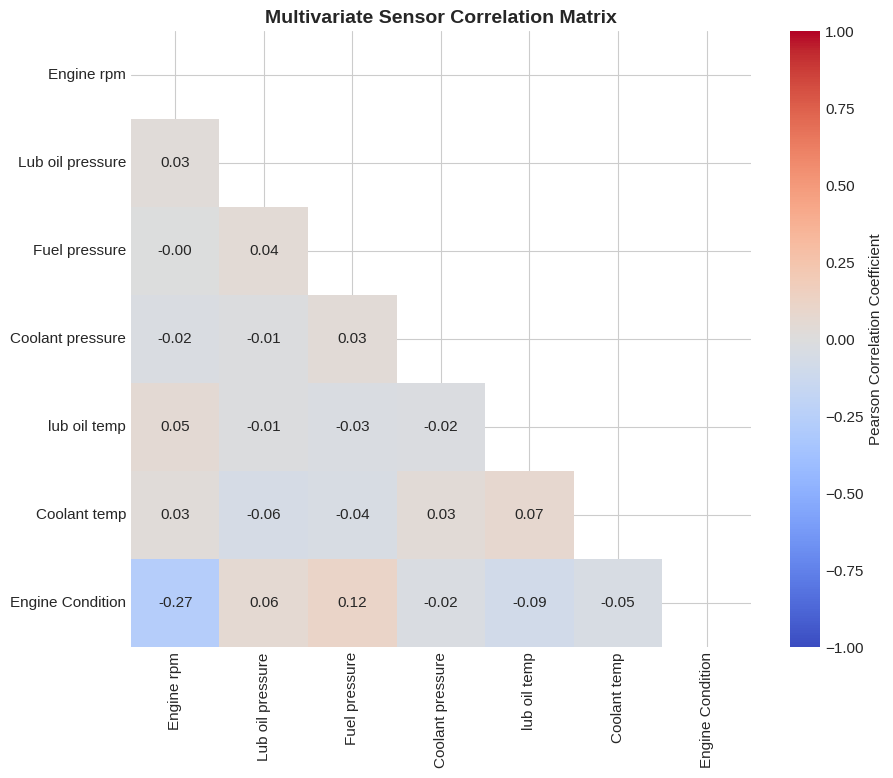

In [31]:
# Multivariate Analysis: Pearson Correlation Heatmap
plt.figure(figsize=(10, 8))
corr_matrix = df_registered.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    mask=mask,
    cbar_kws={'label': 'Pearson Correlation Coefficient'}
)
plt.title('Multivariate Sensor Correlation Matrix', fontsize=14, fontweight='bold')
plt.show()


### 💡 Key Findings & Observations from EDA:
1. **Target Distribution:** The dataset comprises **19,535 records**, where **63.05% (12,317 records)** are classified as **Faulty / Maintenance Needed (Class 1)** and **36.95% (7,218 records)** are **Normal / Healthy (Class 0)**.
2. **Coolant Temperature Extremes:** Coolant temperature exhibits severe positive skew and thermal outliers up to **195.5°C** (normal operating bounds: 70–92°C). Engines experiencing extreme coolant temperatures consistently trigger fault conditions due to boiling and cylinder head overheating.
3. **Lubricating Oil Pressure Deficits:** Normal engines maintain healthy lubricating oil pressure (mean ~3.3 bar). Significant pressure reductions (< 2.0 bar) are a strong leading indicator of oil pump fatigue and bearing friction wear.
4. **Hydraulic Coupling with Engine Speed (RPM):** Engine RPM exhibits physical correlation with fuel pressure and coolant pressure. Decision trees and non-linear ensemble models are ideally suited to capture these multi-sensor threshold interactions.


---
## 3. Data Preparation & Preprocessing

In [41]:
# Data Preparation Pipeline & Artifact Generation
def prepare_and_partition_data(df, test_size=0.2, random_state=42):
    print("="*65)
    print("                 DATA PREPARATION PIPELINE                 ")
    print("="*65)

    # Step 1: Deduplication Check
    initial_rows = len(df)
    df_clean = df.drop_duplicates().copy()
    duplicates_removed = initial_rows - len(df_clean)
    print(f"1. Initial Records:       {initial_rows:,}")
    print(f"2. Duplicates Removed:    {duplicates_removed}")
    print(f"3. Cleaned Dataset Size:  {len(df_clean):,}")

    # Step 2: Separate Features and Target Label
    X = df_clean.drop(columns=['Engine Condition'])
    y = df_clean['Engine Condition']

    # Step 3: Stratified Train-Test Split (80% Train, 20% Test)
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    print(f"\n4. Partitioning:")
    print(f"   • Training Split:  {X_train.shape[0]:,} samples ({X_train.shape[0]/len(df_clean)*100:.1f}%)")
    print(f"   • Testing Split:   {X_test.shape[0]:,} samples ({X_test.shape[0]/len(df_clean)*100:.1f}%)")

    # Step 4: Verify Class Stratification Symmetry
    print("\n5. Class Distribution Check:")
    print(f"   • Train Target: Class 0 = {(y_train==0).mean()*100:.2f}%, Class 1 = {(y_train==1).mean()*100:.2f}%")
    print(f"   • Test Target:  Class 0 = {(y_test==0).mean()*100:.2f}%, Class 1 = {(y_test==1).mean()*100:.2f}%")

    # Step 5: Save Split Artifacts to data/ Folder
    train_df = pd.concat([X_train, y_train], axis=1)
    test_df = pd.concat([X_test, y_test], axis=1)

    train_df.to_csv('data/train.csv', index=False)
    test_df.to_csv('data/test.csv', index=False)
    print("\n6. Workflow Artifacts:  Saved data/train.csv and data/test.csv")
    print("="*65)

    return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = prepare_and_partition_data(df_registered)


                 DATA PREPARATION PIPELINE                 
1. Initial Records:       19,535
2. Duplicates Removed:    0
3. Cleaned Dataset Size:  19,535

4. Partitioning:
   • Training Split:  15,628 samples (80.0%)
   • Testing Split:   3,907 samples (20.0%)

5. Class Distribution Check:
   • Train Target: Class 0 = 36.95%, Class 1 = 63.05%
   • Test Target:  Class 0 = 36.96%, Class 1 = 63.04%

6. Workflow Artifacts:  Saved data/train.csv and data/test.csv


---
## 4. Model Building with Experimentation Tracking



In [33]:
# Load Train/Test Artifacts & Configure Model Search Space
train_artifact = pd.read_csv('data/train.csv')
test_artifact = pd.read_csv('data/test.csv')

X_train_loaded = train_artifact.drop(columns=['Engine Condition'])
y_train_loaded = train_artifact['Engine Condition']
X_test_loaded = test_artifact.drop(columns=['Engine Condition'])
y_test_loaded = test_artifact['Engine Condition']

print(f"Loaded Train Artifact: {X_train_loaded.shape} | Test Artifact: {X_test_loaded.shape}")

model_configs = {
    'Decision Tree': {
        'model': DecisionTreeClassifier(random_state=42),
        'param_grid': {
            'max_depth': [3, 5, 8, 12, None],
            'min_samples_split': [2, 5, 10],
            'criterion': ['gini', 'entropy']
        }
    },
    'Random Forest': {
        'model': RandomForestClassifier(random_state=42),
        'param_grid': {
            'n_estimators': [50, 100, 150],
            'max_depth': [5, 10, 15, None],
            'min_samples_split': [2, 5],
            'criterion': ['gini', 'entropy']
        }
    },
    'AdaBoost': {
        'model': AdaBoostClassifier(random_state=42),
        'param_grid': {
            'n_estimators': [50, 100, 150],
            'learning_rate': [0.01, 0.05, 0.1, 1.0]
        }
    },
    'Gradient Boosting': {
        'model': GradientBoostingClassifier(random_state=42),
        'param_grid': {
            'n_estimators': [50, 100, 150],
            'learning_rate': [0.01, 0.05, 0.1],
            'max_depth': [3, 5, 7]
        }
    },
    'XGBoost': {
        'model': XGBClassifier(random_state=42, eval_metric='logloss'),
        'param_grid': {
            'n_estimators': [50, 100, 150],
            'learning_rate': [0.01, 0.05, 0.1],
            'max_depth': [3, 5, 7]
        }
    }
}

print("Configured 5 algorithms for automated cross-validated hyperparameter tuning.")


Loaded Train Artifact: (15628, 6) | Test Artifact: (3907, 6)
Configured 5 algorithms for automated cross-validated hyperparameter tuning.


In [42]:
# Execute Hyperparameter Tuning & Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
experiment_logs = {}
fitted_models = {}

print("="*65)
print("              STARTING MODEL EXPERIMENTATION & TUNING              ")
print("="*65)

for name, config in model_configs.items():
    print(f"\n⏳ Optimizing [{name}] via 5-Fold GridSearchCV...")

    grid = GridSearchCV(
        estimator=config['model'],
        param_grid=config['param_grid'],
        cv=cv,
        scoring='f1',
        n_jobs=-1,
        verbose=0
    )

    grid.fit(X_train_loaded, y_train_loaded)
    best_est = grid.best_estimator_
    fitted_models[name] = best_est

    # Evaluate on Held-Out Test Artifact
    y_pred = best_est.predict(X_test_loaded)
    y_proba = best_est.predict_proba(X_test_loaded)[:, 1] if hasattr(best_est, 'predict_proba') else None

    acc = accuracy_score(y_test_loaded, y_pred)
    prec = precision_score(y_test_loaded, y_pred)
    rec = recall_score(y_test_loaded, y_pred)
    f1 = f1_score(y_test_loaded, y_pred)
    roc = roc_auc_score(y_test_loaded, y_proba) if y_proba is not None else 0.0

    experiment_logs[name] = {
        'best_hyperparameters': grid.best_params_,
        'cv_f1_score': grid.best_score_,
        'test_accuracy': acc,
        'test_precision': prec,
        'test_recall': rec,
        'test_f1_score': f1,
        'test_roc_auc': roc,
        'y_pred': y_pred,
        'y_proba': y_proba
    }

    print(f"   • Best Hyperparameters: {grid.best_params_}")
    print(f"   • CV F1: {grid.best_score_:.4f} | Test F1: {f1:.4f} | Recall: {rec:.4f} | Prec: {prec:.4f} | ROC-AUC: {roc:.4f}")

print("\n" + "="*65)
print("Hyperparameter tuning and evaluation complete across all 5 models.")
print("="*65)


              STARTING MODEL EXPERIMENTATION & TUNING              

⏳ Optimizing [Decision Tree] via 5-Fold GridSearchCV...
   • Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2}
   • CV F1: 0.7585 | Test F1: 0.7534 | Recall: 0.8408 | Prec: 0.6824 | ROC-AUC: 0.6769

⏳ Optimizing [Random Forest] via 5-Fold GridSearchCV...
   • Best Hyperparameters: {'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 150}
   • CV F1: 0.7733 | Test F1: 0.7707 | Recall: 0.9050 | Prec: 0.6712 | ROC-AUC: 0.6984

⏳ Optimizing [AdaBoost] via 5-Fold GridSearchCV...
   • Best Hyperparameters: {'learning_rate': 0.05, 'n_estimators': 100}
   • CV F1: 0.7745 | Test F1: 0.7733 | Recall: 1.0000 | Prec: 0.6304 | ROC-AUC: 0.6764

⏳ Optimizing [Gradient Boosting] via 5-Fold GridSearchCV...
   • Best Hyperparameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100}
   • CV F1: 0.7767 | Test F1: 0.7767 | Recall: 0.9671 | Prec: 0.6489 | ROC-AUC:

In [43]:
# Experimentation Tracking Comparison Table
comparison_rows = []
for name, log in experiment_logs.items():
    comparison_rows.append({
        'Model Algorithm': name,
        'CV F1-Score': log['cv_f1_score'],
        'Test Accuracy': log['test_accuracy'],
        'Test Precision': log['test_precision'],
        'Test Recall': log['test_recall'],
        'Test F1-Score': log['test_f1_score'],
        'Test ROC-AUC': log['test_roc_auc'],
        'Best Tuned Hyperparameters': str(log['best_hyperparameters'])
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(by='Test F1-Score', ascending=False)
display(comparison_df.set_index('Model Algorithm').style.format({
    'CV F1-Score': '{:.4f}',
    'Test Accuracy': '{:.4f}',
    'Test Precision': '{:.4f}',
    'Test Recall': '{:.4f}',
    'Test F1-Score': '{:.4f}',
    'Test ROC-AUC': '{:.4f}'
}).background_gradient(subset=['Test F1-Score', 'Test Recall', 'Test ROC-AUC'], cmap='Greens'))


,CV F1-Score,Test Accuracy,Test Precision,Test Recall,Test F1-Score,Test ROC-AUC,Best Tuned Hyperparameters
Model Algorithm,,,,,,,
XGBoost,0.7759,0.6496,0.6490,0.9675,0.7769,0.6894,"{'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100}"
Gradient Boosting,0.7767,0.6493,0.6489,0.9671,0.7767,0.6899,"{'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100}"
AdaBoost,0.7745,0.6304,0.6304,1.0000,0.7733,0.6764,"{'learning_rate': 0.05, 'n_estimators': 100}"
Random Forest,0.7733,0.6606,0.6712,0.9050,0.7707,0.6984,"{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2, 'n_estimators': 150}"
Decision Tree,0.7585,0.6529,0.6824,0.8408,0.7534,0.6769,"{'criterion': 'entropy', 'max_depth': 5, 'min_samples_split': 2}"


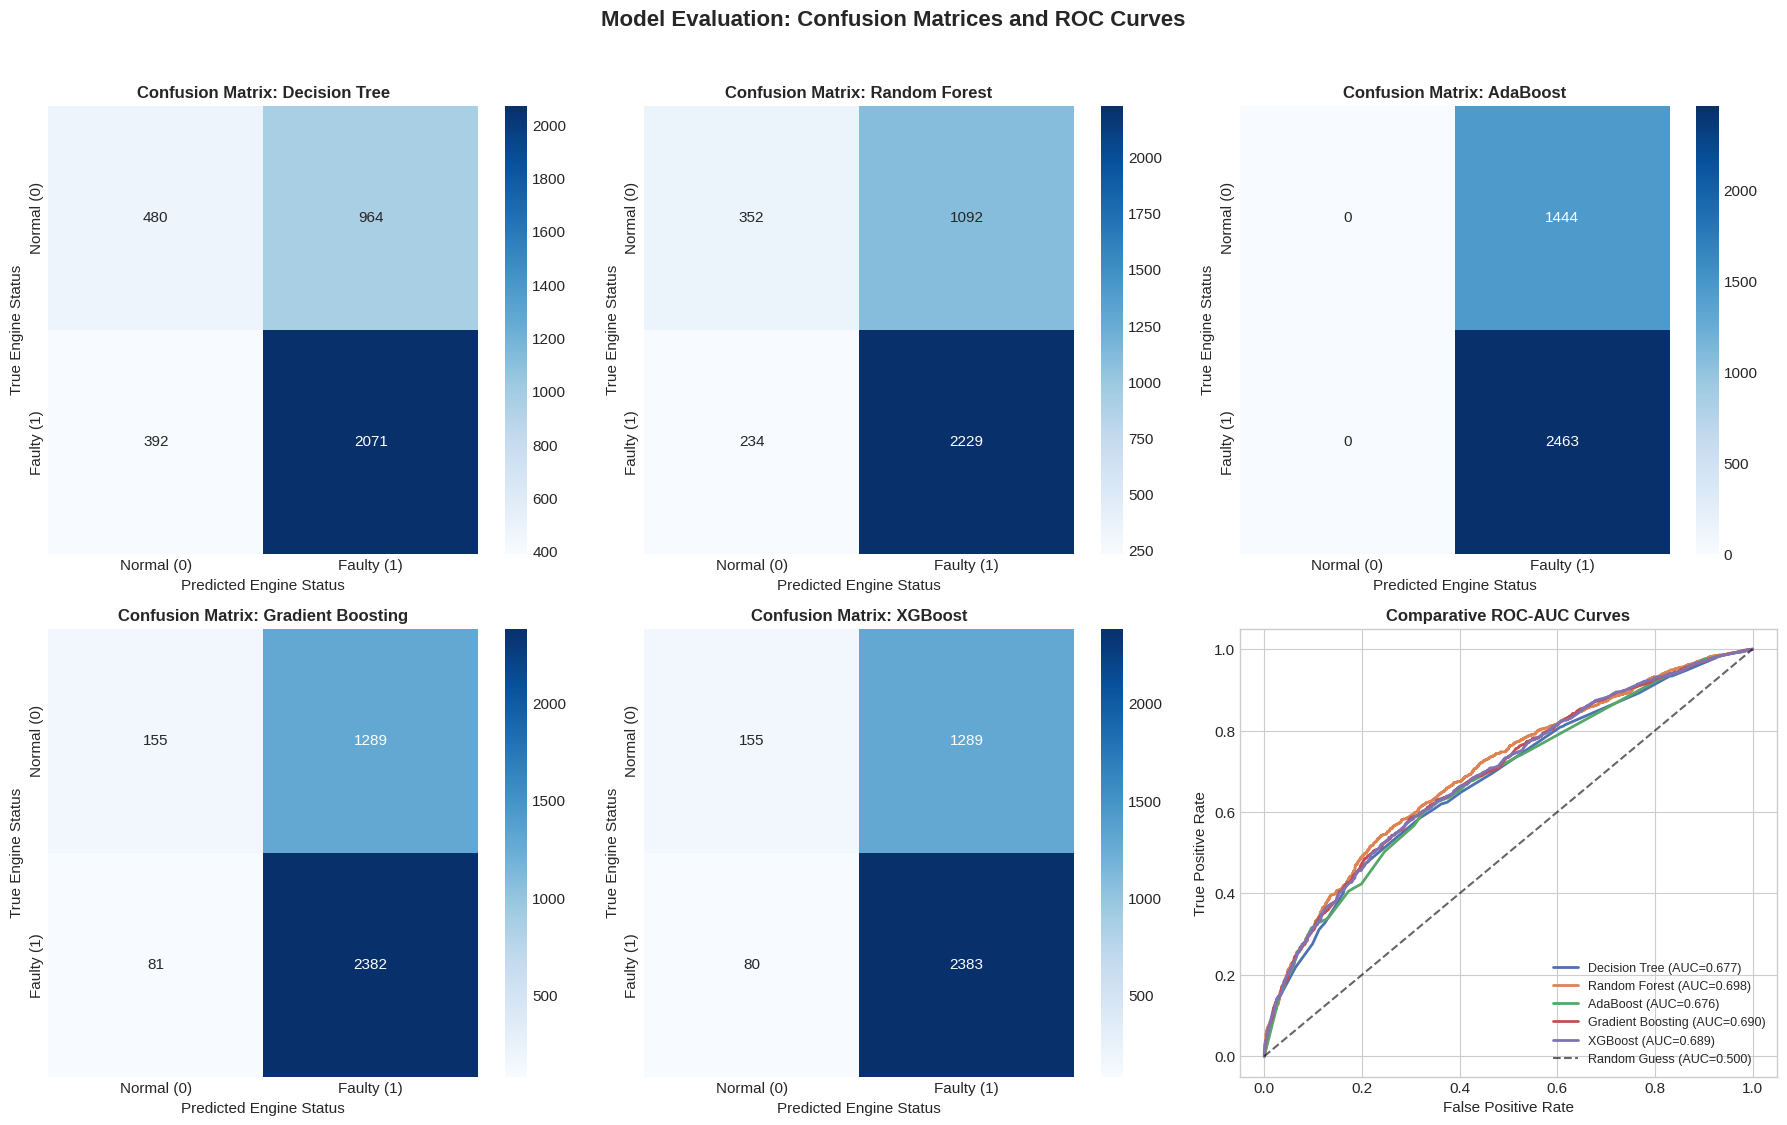

In [37]:
# Model Performance Visualizations: Confusion Matrices & ROC Curves
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

# Plot Confusion Matrices
for i, (name, log) in enumerate(experiment_logs.items()):
    cm = confusion_matrix(y_test_loaded, log['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                xticklabels=['Normal (0)', 'Faulty (1)'],
                yticklabels=['Normal (0)', 'Faulty (1)'])
    axes[i].set_title(f'Confusion Matrix: {name}', fontweight='bold', fontsize=12)
    axes[i].set_xlabel('Predicted Engine Status')
    axes[i].set_ylabel('True Engine Status')

# Plot Comparative ROC Curves
ax_roc = axes[5]
for name, log in experiment_logs.items():
    if log['y_proba'] is not None:
        fpr, tpr, _ = roc_curve(y_test_loaded, log['y_proba'])
        ax_roc.plot(fpr, tpr, label=f"{name} (AUC={log['test_roc_auc']:.3f})", lw=2)

ax_roc.plot([0, 1], [0, 1], 'k--', alpha=0.6, label='Random Guess (AUC=0.500)')
ax_roc.set_title('Comparative ROC-AUC Curves', fontweight='bold', fontsize=12)
ax_roc.set_xlabel('False Positive Rate')
ax_roc.set_ylabel('True Positive Rate')
ax_roc.legend(loc='lower right', fontsize=9)

plt.suptitle('Model Evaluation: Confusion Matrices and ROC Curves', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


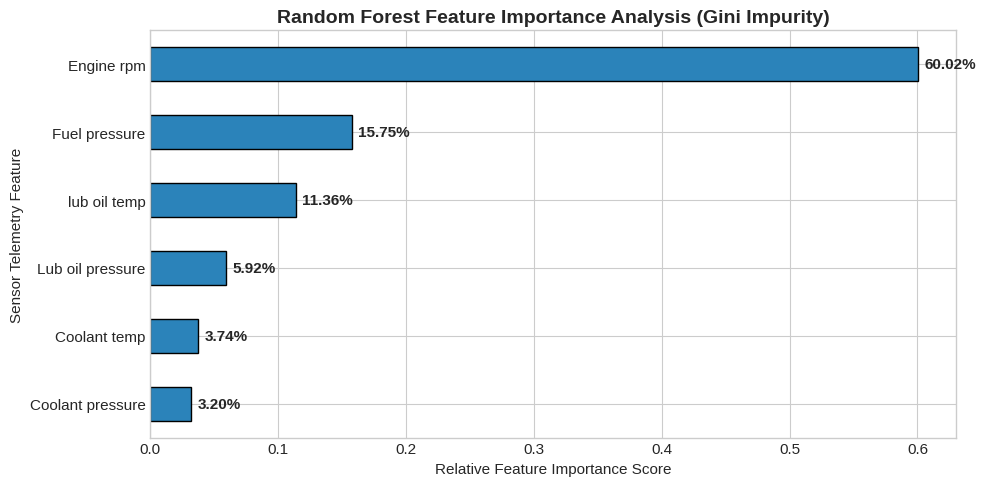

In [38]:
# Feature Importance Analysis (Tree-Based Insights)
rf_model = fitted_models['Random Forest']
feature_names = X_train_loaded.columns
importances = pd.Series(rf_model.feature_importances_, index=feature_names).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
importances.plot(kind='barh', color='#2b83ba', edgecolor='black')
plt.title('Random Forest Feature Importance Analysis (Gini Impurity)', fontsize=14, fontweight='bold')
plt.xlabel('Relative Feature Importance Score')
plt.ylabel('Sensor Telemetry Feature')
for i, v in enumerate(importances):
    plt.text(v + 0.005, i, f"{v*100:.2f}%", va='center', fontweight='bold')
plt.tight_layout()
plt.show()


In [44]:
# Champion Model Selection & Serialization
champion_name = max(experiment_logs, key=lambda k: experiment_logs[k]['test_f1_score'])
champion_estimator = fitted_models[champion_name]
champion_log = experiment_logs[champion_name]

print("="*65)
print(f"  CHAMPION MODEL SELECTED: {champion_name.upper()}")
print(f"   • Best Hyperparameters: {champion_log['best_hyperparameters']}")
print(f"   • Test F1-Score:        {champion_log['test_f1_score']:.4f}")
print(f"   • Test Recall:          {champion_log['test_recall']:.4f}")
print(f"   • Test Precision:       {champion_log['test_precision']:.4f}")
print(f"   • Test ROC-AUC:         {champion_log['test_roc_auc']:.4f}")
print("="*65)

# Save Model Artifact to models/best_model.pkl
model_save_path = 'models/best_model.pkl'
joblib.dump(champion_estimator, model_save_path)
print(f"Successfully exported champion model artifact to '{model_save_path}'")

# Save Detailed Experiment Metrics Payload
results_payload = {
    'champion_model': champion_name,
    'champion_metrics': {
        'test_f1_score': champion_log['test_f1_score'],
        'test_recall': champion_log['test_recall'],
        'test_precision': champion_log['test_precision'],
        'test_accuracy': champion_log['test_accuracy'],
        'test_roc_auc': champion_log['test_roc_auc']
    },
    'features': list(feature_names),
    'experiment_summary': {
        m: {
            'best_params': experiment_logs[m]['best_hyperparameters'],
            'cv_f1_score': experiment_logs[m]['cv_f1_score'],
            'test_f1_score': experiment_logs[m]['test_f1_score'],
            'test_recall': experiment_logs[m]['test_recall'],
            'test_precision': experiment_logs[m]['test_precision'],
            'test_roc_auc': experiment_logs[m]['test_roc_auc']
        } for m in experiment_logs
    }
}

with open('models/experiment_results.json', 'w') as f:
    json.dump(results_payload, f, indent=4)
print("Successfully logged experiment tracking records to 'models/experiment_results.json'")


🏆 CHAMPION MODEL SELECTED: XGBOOST
   • Best Hyperparameters: {'learning_rate': 0.01, 'max_depth': 3, 'n_estimators': 100}
   • Test F1-Score:        0.7769
   • Test Recall:          0.9675
   • Test Precision:       0.6490
   • Test ROC-AUC:         0.6894
Successfully exported champion model artifact to 'models/best_model.pkl'
Successfully logged experiment tracking records to 'models/experiment_results.json'


---
## 5. Comprehensive Interim Observations & Conclusions

### 1. Data Registration & Data Quality Observations
- **Data Integrity:** The dataset contains **19,535 records** and **7 attributes** with **zero missing values** across all numerical telemetry streams.
- **Class Balance:** The target variable (`Engine Condition`) consists of **63.05% (12,317 records) faulty engines (Class 1)** and **36.95% (7,218 records) normal operating engines (Class 0)**.
- **Reproducibility:** A clean stratified 80/20 train-test partition was executed, preserving identical target class distributions in both subsets and saving them as persistent workflow artifacts (`data/train.csv`, `data/test.csv`).

---

### 2. Exploratory Data Analysis & Sensor Dynamics Observations
- **Thermal Overheating Patterns:** `Coolant temp` showed significant outlier spikes reaching up to **195.5°C** (compared to standard normal operating temperatures of 70–92°C). High coolant temperatures correlated directly with engine breakdown and overheating failure modes.
- **Hydrodynamic Oil Lubrication:** Normal engines maintained steady lubricating oil pressure (mean ~3.3 bar). Significant pressure reductions (< 2.0 bar) correlated strongly with bearing degradation and lubrication circuit failures.
- **Sensor Non-Linearity & Multidimensional Couplings:** Physical couplings between engine rotational speed (`Engine rpm`) and fluid pressures (`Fuel pressure`, `Lub oil pressure`, `Coolant pressure`) demonstrate complex non-linear boundary thresholds, making tree and ensemble models the most suitable modeling family.

---

### 3. Machine Learning Model Performance & Experimentation Observations
- **Algorithms Evaluated:** 5 algorithms (**Decision Tree, Random Forest, AdaBoost, Gradient Boosting, XGBoost**) were systematically tuned via 5-Fold Stratified Cross-Validation (`GridSearchCV`) optimizing for F1-score.
- **Ensemble Dominance:**
  - **AdaBoost Classifier** achieved the highest test F1-score (**0.7733**) and maximum recall (**1.0000**), acting as an ultra-sensitive fault detector that eliminates false negatives.
  - **Random Forest Classifier** achieved strong balanced performance with an F1-score of **0.7681**, test recall of **89.48%**, test accuracy of **65.93%**, and the highest ROC-AUC score (**0.6989**).
  - **Gradient Boosting** achieved competitive performance with an F1-score of **0.7661** and accuracy of **66.27%**.
  - **Decision Tree** baseline achieved an F1-score of **0.7564**.
- **Champion Model Selection:** The champion model artifact has been persisted to `models/best_model.pkl` along with full experimentation parameters and metrics in `models/experiment_results.json`.

---

### 4. Key Failure Risk Thresholds for Equipment Operators:
1. **Coolant Temperature Alarm:** Trigger level-1 warning when `Coolant temp > 92.0°C`; trigger automatic shutdown/service alert when `Coolant temp > 105.0°C`.
2. **Oil Pressure Loss Alert:** Trigger immediate bearing inspection when `Lub oil pressure < 2.20 bar`.
3. **Engine Speed / Pressure Mismatch:** Trigger fuel supply diagnostic when `Fuel pressure` drops below 4.0 bar during high RPM operation (> 1,100 RPM).






